In [1]:
!pip install -q ultralytics psutil pandas matplotlib

In [2]:
import torch
import time
import psutil
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files
from PIL import Image
from IPython.display import display
from collections import Counter

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    device = "0"
    print("GPU Available:", True)
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")
else:
    device = "cpu"
    print("GPU Available: False")
    print("Using CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch Version: 2.14.1+cpu
GPU Available: False
Using CPU


In [3]:
model = YOLO("yolo11n.pt")

print("VisionPort YOLO Model Loaded Successfully!")
print("Model: YOLO11n")
print("Device:", device)

VisionPort YOLO Model Loaded Successfully!
Model: YOLO11n
Device: cpu


Saving Traffic.jpeg to Traffic.jpeg
Image Uploaded Successfully!
Filename: Traffic.jpeg
Image Dimensions: (451, 679)


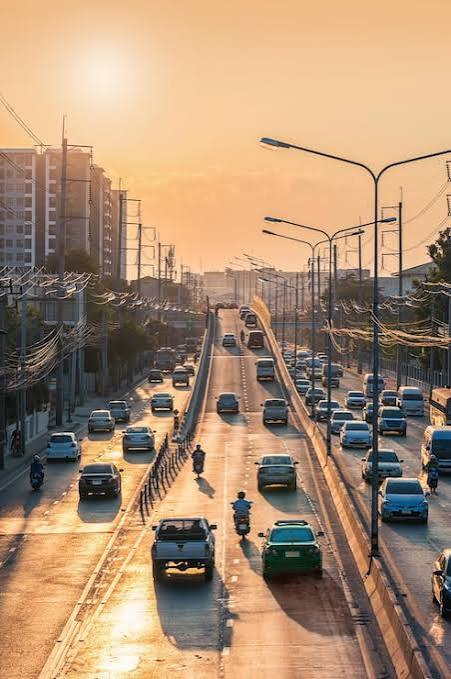

In [4]:
uploaded = files.upload()

filename = next(iter(uploaded.keys()))

image = Image.open(filename).convert("RGB")

print("Image Uploaded Successfully!")
print("Filename:", filename)
print("Image Dimensions:", image.size)

display(image)

In [5]:
print("Performing GPU warm-up...")

warmup_results = model.predict(
    source=image,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

print("Warm-up Completed Successfully!")

Performing GPU warm-up...
Warm-up Completed Successfully!


In [6]:
# Reset GPU memory statistics
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# Start measuring
start_time = time.perf_counter()

results = model.predict(
    source=image,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

# Wait for GPU operations to finish
if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_latency = (end_time - start_time) * 1000

result = results[0]

print("========== INFERENCE PERFORMANCE ==========")
print("Total Inference Latency:", round(total_latency, 2), "ms")
print("===========================================")

========== INFERENCE PERFORMANCE ==========
Total Inference Latency: 250.86 ms


In [7]:
speed = result.speed

preprocess_time = speed["preprocess"]
inference_time = speed["inference"]
postprocess_time = speed["postprocess"]

print("========== EXECUTION BREAKDOWN ==========")

print("Preprocessing Time:",
      round(preprocess_time, 2), "ms")

print("GPU Inference Time:",
      round(inference_time, 2), "ms")

print("Postprocessing Time:",
      round(postprocess_time, 2), "ms")

print("Total Model Pipeline Time:",
      round(preprocess_time + inference_time + postprocess_time, 2),
      "ms")

print("=========================================")

========== EXECUTION BREAKDOWN ==========
Preprocessing Time: 8.65 ms
GPU Inference Time: 237.16 ms
Postprocessing Time: 1.69 ms
Total Model Pipeline Time: 247.5 ms


In [8]:
if torch.cuda.is_available():

    allocated_memory = torch.cuda.memory_allocated(0) / (1024**2)

    reserved_memory = torch.cuda.memory_reserved(0) / (1024**2)

    peak_memory = torch.cuda.max_memory_allocated(0) / (1024**2)

    print("========== GPU MEMORY USAGE ==========")

    print("Allocated GPU Memory:",
          round(allocated_memory, 2), "MB")

    print("Reserved GPU Memory:",
          round(reserved_memory, 2), "MB")

    print("Peak GPU Memory:",
          round(peak_memory, 2), "MB")

    print("======================================")

else:
    print("GPU memory monitoring unavailable on CPU.")

GPU memory monitoring unavailable on CPU.


In [9]:
cpu_usage = psutil.cpu_percent(interval=1)

ram_usage = psutil.virtual_memory().percent

ram_used = psutil.virtual_memory().used / (1024**3)

print("========== SYSTEM RESOURCE USAGE ==========")

print("CPU Usage:", cpu_usage, "%")

print("RAM Usage:", ram_usage, "%")

print("RAM Used:", round(ram_used, 2), "GB")

print("============================================")

========== SYSTEM RESOURCE USAGE ==========
CPU Usage: 56.8 %
RAM Usage: 13.4 %
RAM Used: 1.38 GB


In [10]:
num_iterations = 20

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.perf_counter()

for i in range(num_iterations):

    model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time = end_time - start_time

throughput = num_iterations / total_time

average_latency = (total_time / num_iterations) * 1000

print("========== THROUGHPUT RESULTS ==========")

print("Total Images:", num_iterations)

print("Total Time:", round(total_time, 3), "seconds")

print("Average Latency:", round(average_latency, 2), "ms")

print("Throughput:", round(throughput, 2), "images/second")

print("========================================")

========== THROUGHPUT RESULTS ==========
Total Images: 20
Total Time: 2.593 seconds
Average Latency: 129.64 ms
Throughput: 7.71 images/second


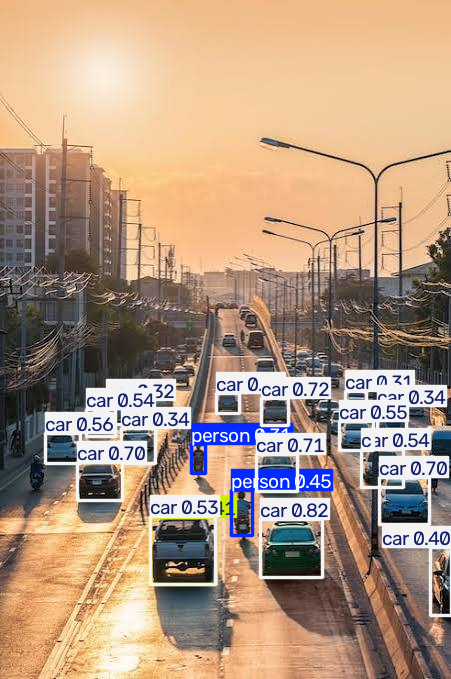

========== DETECTION RESULTS ==========
Total Objects Detected: 19
car : 16
person : 2
truck : 1


In [11]:
result = results[0]

# Display annotated image
annotated_image = result.plot()

display(
    Image.fromarray(annotated_image[:, :, ::-1])
)

# Count detected objects
object_names = []

for box in result.boxes:
    class_id = int(box.cls[0])
    object_names.append(result.names[class_id])

object_counts = Counter(object_names)

print("========== DETECTION RESULTS ==========")

print("Total Objects Detected:", len(object_names))

for name, count in object_counts.items():
    print(name, ":", count)

print("=======================================")

In [12]:
performance_data = {
    "Metric": [
        "Preprocessing",
        "GPU Inference",
        "Postprocessing",
        "Total Pipeline Latency",
        "Average Request Latency",
        "Throughput",
        "CPU Usage",
        "RAM Usage"
    ],

    "Value": [
        round(preprocess_time, 2),
        round(inference_time, 2),
        round(postprocess_time, 2),
        round(preprocess_time + inference_time + postprocess_time, 2),
        round(average_latency, 2),
        round(throughput, 2),
        round(cpu_usage, 2),
        round(ram_usage, 2)
    ],

    "Unit": [
        "ms", "ms", "ms", "ms",
        "ms", "images/sec", "%", "%"
    ]
}

df = pd.DataFrame(performance_data)

print("VISIONPORT PERFORMANCE REPORT")

display(df)

VISIONPORT PERFORMANCE REPORT


,Metric,Value,Unit
0,Preprocessing,8.65,ms
1,GPU Inference,237.16,ms
2,Postprocessing,1.69,ms
3,Total Pipeline Latency,247.50,ms
4,Average Request Latency,129.64,ms
5,Throughput,7.71,images/sec
6,CPU Usage,56.80,%
7,RAM Usage,13.40,%


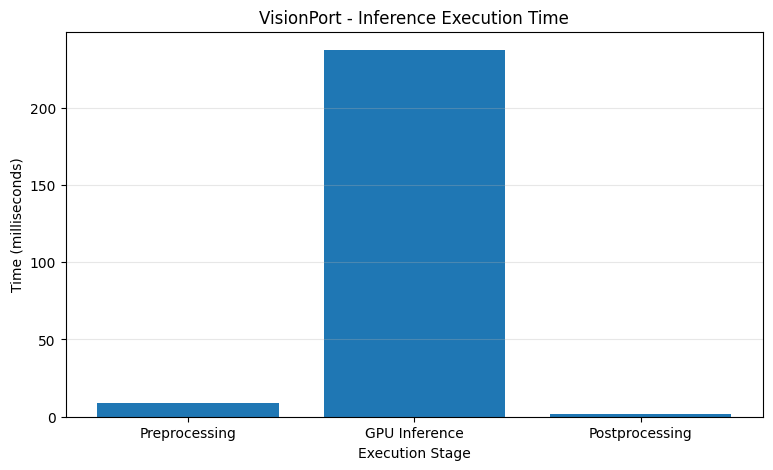

In [13]:
stages = [
    "Preprocessing",
    "GPU Inference",
    "Postprocessing"
]

times = [
    preprocess_time,
    inference_time,
    postprocess_time
]

plt.figure(figsize=(9, 5))

plt.bar(stages, times)

plt.title("VisionPort - Inference Execution Time")
plt.xlabel("Execution Stage")
plt.ylabel("Time (milliseconds)")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [14]:
stage_times = {
    "Preprocessing": preprocess_time,
    "GPU Inference": inference_time,
    "Postprocessing": postprocess_time
}

bottleneck = max(stage_times, key=stage_times.get)

print("========== BOTTLENECK ANALYSIS ==========")

print("Slowest Execution Stage:", bottleneck)

print("Execution Time:", round(stage_times[bottleneck], 2), "ms")

if bottleneck == "Preprocessing":
    print("Observation: Image preparation is taking the most time.")
    print("Suggestion: Optimize image resizing and preprocessing.")

elif bottleneck == "GPU Inference":
    print("Observation: Neural network execution is taking the most time.")
    print("Suggestion: Try TensorRT, FP16 or a smaller model.")

else:
    print("Observation: Prediction processing is taking the most time.")
    print("Suggestion: Optimize detection filtering and NMS.")

print("=========================================")

========== BOTTLENECK ANALYSIS ==========
Slowest Execution Stage: GPU Inference
Execution Time: 237.16 ms
Observation: Neural network execution is taking the most time.
Suggestion: Try TensorRT, FP16 or a smaller model.
